# CIS*4020 Group 10 - Project

**Members**
- Aeyan Siddiqi
- Ankush Madharha
- Saad Shafiq
- Aryan Qureshi 

**Data:** download "Predict Students' Dropout and Academic Success" data and point `DATA_DIR` at the CSVs
(`https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success`).

# Gather Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__)

DATA_DIR = "content/"   # <-- put the downloaded .csv files here

Matplotlib is building the font cache; this may take a moment.


pandas 3.1.1


In [2]:
FILE = "data.csv"

def load_data():
    missing = not os.path.exists(DATA_DIR)
    if missing:
        raise FileNotFoundError(
            "Couldn't find file(s)."
            "Set DATA_DIR to the folder containing the CSVs."
        )
    print("[info] loading real data from", DATA_DIR)
    return pd.read_csv(os.path.join(DATA_DIR, FILE), sep=";")

raw_data = load_data()
print(f"{FILE}: {raw_data.shape}")
raw_data.head()

[info] loading real data from content/
data.csv: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Clean Data

Each step ahead will state a decision and justification for that decision.

### 1. Fix column names
- Fix `Nacionality` typo and replace with `Nationality`, easier to read.
- Strip the \t in `Daytime/evening attendance\t`, probably a leftover tab character.
- convert all columns to snake case ('snake_case') for more standard variable names.

Overall these changes make the data much easier to work with in code and while analyzing.

In [3]:
import re

def fix_name(name: str) -> str:
    # strip gets rid of \t and then do a replace for the type
    name = name.strip().replace("Nacionality", "Nationality").replace("'s", "")
    #snake case
    return re.sub(r"[^0-9a-zA-Z]+", "_", name).strip("_").lower()

df = raw_data.copy()
# fix them
df.columns = [fix_name(c) for c in df.columns]

assert df.columns.is_unique
list(df.columns)


['marital_status',
 'application_mode',
 'application_order',
 'course',
 'daytime_evening_attendance',
 'previous_qualification',
 'previous_qualification_grade',
 'nationality',
 'mother_qualification',
 'father_qualification',
 'mother_occupation',
 'father_occupation',
 'admission_grade',
 'displaced',
 'educational_special_needs',
 'debtor',
 'tuition_fees_up_to_date',
 'gender',
 'scholarship_holder',
 'age_at_enrollment',
 'international',
 'curricular_units_1st_sem_credited',
 'curricular_units_1st_sem_enrolled',
 'curricular_units_1st_sem_evaluations',
 'curricular_units_1st_sem_approved',
 'curricular_units_1st_sem_grade',
 'curricular_units_1st_sem_without_evaluations',
 'curricular_units_2nd_sem_credited',
 'curricular_units_2nd_sem_enrolled',
 'curricular_units_2nd_sem_evaluations',
 'curricular_units_2nd_sem_approved',
 'curricular_units_2nd_sem_grade',
 'curricular_units_2nd_sem_without_evaluations',
 'unemployment_rate',
 'inflation_rate',
 'gdp',
 'target']

### 2. Drop Enrolled Students
We are removing the `Enrolled` students as they do not pretain to what our models are trying to predict. Our question is `Dropout` or `Graduation`, enrolled students have no effect on the final outcome of this project.

In [4]:
n_before = len(df)

# the target is the variable that decides
df = df[df["target"] != "Enrolled"].copy()

# we will create a new column for the binary dropout/not-dropout
df["dropout"] = (df["target"] == "Dropout").astype(int)
df = df.drop(columns="target").reset_index(drop=True)

# print out results
print(f"Dropped rows: {n_before - len(df)}")
print(df["dropout"].value_counts().rename({0: "Graduate", 1: "Dropout"}))
print(f"Dropout rate: {df['dropout'].mean():.2%}")

Dropped rows: 794
dropout
Graduate    2209
Dropout     1421
Name: count, dtype: int64
Dropout rate: 39.15%


### 3. Remove Leakage
There are 12 `curricular_units_x` columns that declare the performance for semesters per student. The issue is that these will quickly fall to 0 if a student drops out, as they do not attend the class. This will leak the result of the student to the models, and increase accuracy without giving us any meaningful insights.

In [5]:
# get and drop them
non_curricular_cols = [c for c in df.columns if c[:16] != 'curricular_units']
df = df[non_curricular_cols]

list(df.columns)

['marital_status',
 'application_mode',
 'application_order',
 'course',
 'daytime_evening_attendance',
 'previous_qualification',
 'previous_qualification_grade',
 'nationality',
 'mother_qualification',
 'father_qualification',
 'mother_occupation',
 'father_occupation',
 'admission_grade',
 'displaced',
 'educational_special_needs',
 'debtor',
 'tuition_fees_up_to_date',
 'gender',
 'scholarship_holder',
 'age_at_enrollment',
 'international',
 'unemployment_rate',
 'inflation_rate',
 'gdp',
 'dropout']

### 4. Map Categories
- **Occupations:** There are many detailed occupations groups, for better predicitions, we will group them into larger containing groups. 
- **Qualifications:** 17–34 codes describe one education ladder. We will group them into `none / basic / secondary / post-secondary / higher` + `Unknown`.
- **Nationality:** Due to this dataset we know that it is 97.5% Portuguese, the other 20 nationalities have ≤ 38 rows each, and the column duplicates `international` (international only defines if `nationality != 1`). We will drop it.

In [6]:
OCCUPATION_GROUPS = {
    0: "Student", 1: "Managers/Directors", 2: "Professionals/Scientists", 3: "Technicians",
    4: "Administrative", 5: "Services/Sales", 6: "Agriculture", 7: "Skilled trades",
    8: "Machine operators", 9: "Unskilled", 10: "Armed forces",
}

QUALIFICATION_LEVELS = {
    "none":           [35, 36],
    "basic":          [9, 10, 11, 12, 14, 15, 19, 26, 27, 29, 30, 37, 38],   # < completed secondary
    "secondary":      [1, 13, 18, 20, 22, 25, 31, 33],                       # 12th year / equivalent
    "post-secondary": [39, 42],                                              # technological / professional
    "higher":         [2, 3, 4, 5, 6, 40, 41, 43, 44],                       # bachelor / doctorate
    "Unknown":        [34],
}

def get_occupation_group(code: int) -> str:
    if code in (90, 99):
        return "Unknown"
    if code > 100: # map to major group (101-103 -> armed forces)
        code = (code - 100) // 10 or 10
    return OCCUPATION_GROUPS[code]

QUAL_MAP = {code: lvl for lvl, codes in QUALIFICATION_LEVELS.items() for code in codes}

# map occupations and qualifications

for col in ("mother_occupation", "father_occupation"):
    df[col] = df[col].map(get_occupation_group)
for col in ("mother_qualification", "father_qualification", "previous_qualification"):
    unmapped = set(df[col].unique()) - set(QUAL_MAP)
    assert not unmapped, f"{col}: unmapped codes {unmapped}"
    df[col] = df[col].map(QUAL_MAP)
    
# drop nationality (I guess we didn't need to fix the typo)
df = df.drop(columns="nationality")

# count each and compare
for col in ("mother_occupation", "father_occupation", "mother_qualification", "father_qualification", "previous_qualification"):
    print(col, df[col].value_counts().to_dict())


mother_occupation {'Unskilled': 1338, 'Administrative': 679, 'Services/Sales': 441, 'Technicians': 275, 'Professionals/Scientists': 246, 'Skilled trades': 228, 'Student': 143, 'Managers/Directors': 87, 'Unknown': 85, 'Agriculture': 77, 'Machine operators': 29, 'Armed forces': 2}
father_occupation {'Unskilled': 861, 'Skilled trades': 562, 'Services/Sales': 414, 'Technicians': 324, 'Administrative': 319, 'Machine operators': 267, 'Armed forces': 217, 'Agriculture': 196, 'Professionals/Scientists': 150, 'Student': 125, 'Managers/Directors': 113, 'Unknown': 82}
mother_qualification {'basic': 2151, 'secondary': 867, 'higher': 469, 'Unknown': 127, 'post-secondary': 10, 'none': 6}
father_qualification {'basic': 2434, 'secondary': 742, 'higher': 321, 'Unknown': 109, 'post-secondary': 14, 'none': 10}
previous_qualification {'secondary': 3019, 'basic': 212, 'higher': 207, 'post-secondary': 192}


### 5. Final Type Changes
We are going to explicitly translate some column types to categories so they cannot be mistaked for ratio or interval values by the model later.

In [7]:
QUAL_LEVELS = ["none", "basic", "secondary", "post-secondary", "higher", "Unknown"]
binary_cols  = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
                "tuition_fees_up_to_date", "gender", "scholarship_holder", "international", "dropout"]
nominal_cols = ["course", "marital_status", "application_mode", "mother_occupation", "father_occupation"]
qual_cols    = ["mother_qualification", "father_qualification", "previous_qualification"]

df[binary_cols] = df[binary_cols].astype("int8")
for col in nominal_cols:
    df[col] = df[col].astype("category")
for col in qual_cols:
    df[col] = pd.Categorical(df[col], categories=QUAL_LEVELS) 

# print final result of cleaning
df.head()

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,mother_qualification,father_qualification,mother_occupation,father_occupation,admission_grade,displaced,educational_special_needs,debtor,tuition_fees_up_to_date,gender,scholarship_holder,age_at_enrollment,international,unemployment_rate,inflation_rate,gdp,dropout
0,1,17,5,171,1,secondary,122.0,basic,basic,Services/Sales,Unskilled,127.3,1,0,0,1,1,0,20,0,10.8,1.4,1.74,1
1,1,15,1,9254,1,secondary,160.0,secondary,higher,Technicians,Technicians,142.5,1,0,0,0,1,0,19,0,13.9,-0.3,0.79,0
2,1,1,5,9070,1,secondary,122.0,basic,basic,Unskilled,Unskilled,124.8,1,0,0,0,1,0,19,0,10.8,1.4,1.74,1
3,1,17,2,9773,1,secondary,122.0,basic,basic,Services/Sales,Technicians,119.6,1,0,0,1,0,0,20,0,9.4,-0.8,-3.12,0
4,2,39,1,8014,0,secondary,100.0,basic,basic,Unskilled,Unskilled,141.5,0,0,0,1,0,0,45,0,13.9,-0.3,0.79,0


# Exploratory Data Analysis

Now that the data is clean, we want to look at it before building any models. Our question from the proposal was:

> **Does a student's background significantly affect their chances of dropping out?**

The main thing we'll use is the **dropout rate**: out of all the students in a group, what % dropped out. The overall dropout rate is **39.15%**, so if a group is a lot higher or lower than that, it's probably worth paying attention to.

We are working with the cleaned `df` from above and not changing it in this section (only making copies for plots).

### 1. Quick Overview
First a quick check: shape, missing values, and summary stats for the numeric columns.

In [8]:
print("shape:", df.shape)
print("missing values:", df.isna().sum().sum())

numeric_cols = ["age_at_enrollment", "admission_grade", "previous_qualification_grade",
                "application_order", "unemployment_rate", "inflation_rate", "gdp"]
df[numeric_cols].describe().round(2)

shape: (3630, 24)
missing values: 0


,age_at_enrollment,admission_grade,previous_qualification_grade,application_order,unemployment_rate,inflation_rate,gdp
count,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00
mean,23.46,127.29,132.92,1.75,11.63,1.23,-0.01
std,7.83,14.61,13.24,1.33,2.67,1.38,2.26
min,17.00,95.00,95.00,0.00,7.60,-0.80,-4.06
25%,19.00,118.00,125.00,1.00,9.40,0.30,-1.70
50%,20.00,126.50,133.10,1.00,11.10,1.40,0.32
75%,25.00,135.10,140.00,2.00,13.90,2.60,1.79
max,70.00,190.00,190.00,6.00,16.20,3.70,3.51


- No missing values, so we don't need to change anything.
- Most students are young (median age 20), but the max is 70 so there's a long tail of older students.
- Grades are on a 0-200 scale and look normal (95 to 190).
- `unemployment_rate`, `inflation_rate` and `gdp` only have about 10 different values each. They're national numbers for the year the student enrolled, not something about the student themselves.

### 2. Target Balance
How many graduates vs dropouts do we have?

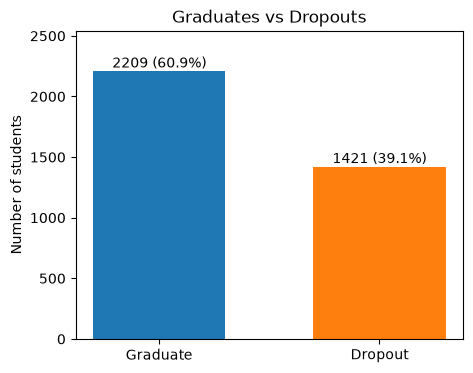

In [9]:
GRAD_COLOR = "#1f77b4"
DROP_COLOR = "#ff7f0e"
OVERALL_RATE = df["dropout"].mean()

counts = df["dropout"].value_counts().rename({0: "Graduate", 1: "Dropout"})

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=[GRAD_COLOR, DROP_COLOR], width=0.6)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 30, f"{n} ({n / len(df):.1%})", ha="center")
ax.set_title("Graduates vs Dropouts")
ax.set_ylabel("Number of students")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

The classes are a bit imbalanced (61% / 39%) but not too badly. 

### 3. Helper Function
Most of our plots are "dropout rate per group", so we made one small function to do this instead of copying the same code over and over. The dashed line is the overall dropout rate (39%).

In [10]:
def plot_dropout_rate(col, ax, labels=None, sort=False, title=None):
    stats = df.groupby(col, observed=True)["dropout"].agg(["mean", "count"])
    if labels is not None:
        stats = stats.rename(index=labels)
    if sort:
        stats = stats.sort_values("mean")

    names = [f"{name} (n={n})" for name, n in zip(stats.index, stats["count"])]
    ax.barh(names, stats["mean"], color=DROP_COLOR, height=0.6)
    ax.axvline(OVERALL_RATE, color="gray", linestyle="--", linewidth=1)

    for i, rate in enumerate(stats["mean"]):
        ax.text(rate + 0.01, i, f"{rate:.0%}", va="center", fontsize=9)

    ax.set_xlim(0, 1.1)
    ax.set_xlabel("Dropout rate")
    ax.set_title(title or col)
    return stats

### 4. Financial Situation

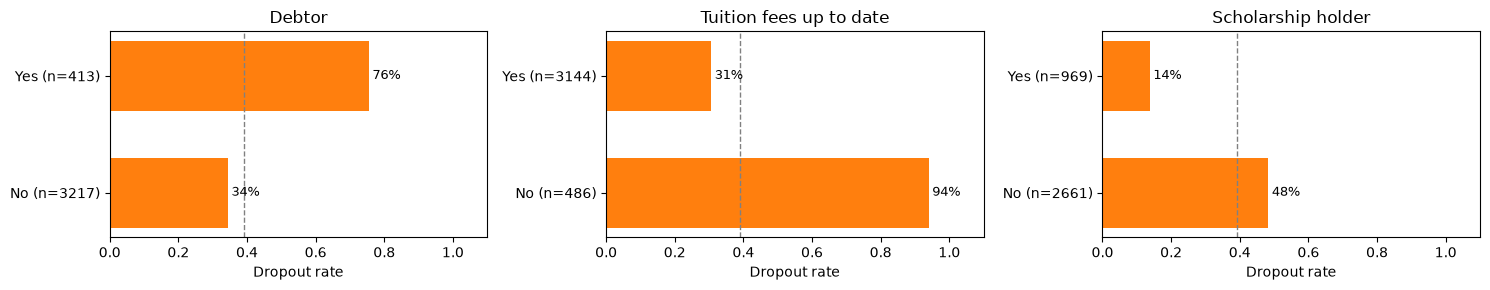

In [11]:
yes_no = {0: "No", 1: "Yes"}

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
plot_dropout_rate("debtor", axes[0], labels=yes_no, title="Debtor")
plot_dropout_rate("tuition_fees_up_to_date", axes[1], labels=yes_no, title="Tuition fees up to date")
plot_dropout_rate("scholarship_holder", axes[2], labels=yes_no, title="Scholarship holder")
plt.tight_layout()
plt.show()

These are the biggest differences in the whole dataset:
- Students whose **tuition is not up to date** dropped out **94%** of the time, compared to 31% for students who are up to date.
- **Debtors** dropped out 76% of the time vs 34% for non-debtors.
- **Scholarship holders** only dropped out 14% of the time vs 48% for everyone else.

So money problems are very strongly linked to dropping out. 

### 5. Personal and Demographic
#### Age at enrollment

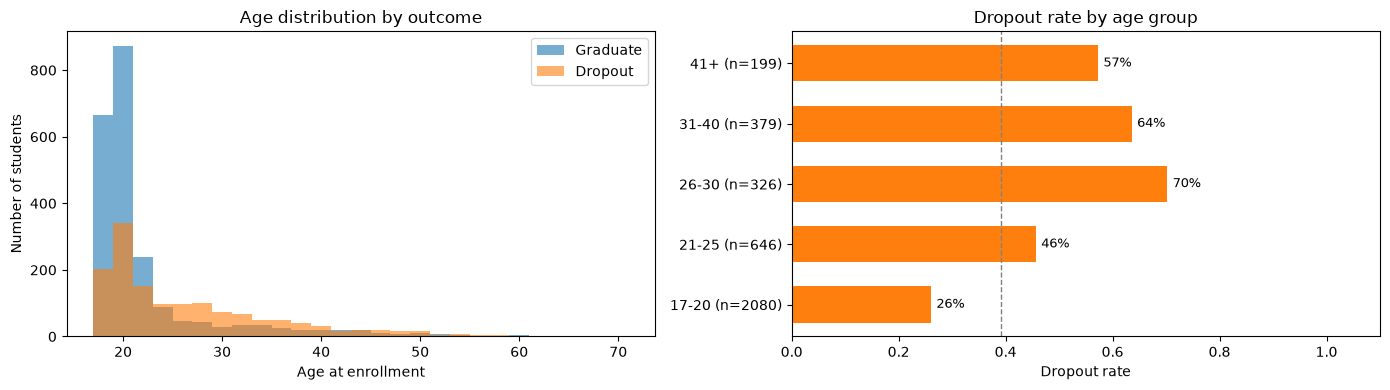

median age  -> graduates: 19.0 | dropouts: 23.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

bins = range(17, 72, 2)
axes[0].hist(df.loc[df["dropout"] == 0, "age_at_enrollment"], bins=bins, alpha=0.6, color=GRAD_COLOR, label="Graduate")
axes[0].hist(df.loc[df["dropout"] == 1, "age_at_enrollment"], bins=bins, alpha=0.6, color=DROP_COLOR, label="Dropout")
axes[0].set_xlabel("Age at enrollment")
axes[0].set_ylabel("Number of students")
axes[0].set_title("Age distribution by outcome")
axes[0].legend()

age_df = df.copy()
age_df["age_group"] = pd.cut(age_df["age_at_enrollment"], bins=[16, 20, 25, 30, 40, 70],
                             labels=["17-20", "21-25", "26-30", "31-40", "41+"])
age_stats = age_df.groupby("age_group", observed=True)["dropout"].agg(["mean", "count"])
names = [f"{g} (n={n})" for g, n in zip(age_stats.index, age_stats["count"])]
axes[1].barh(names, age_stats["mean"], color=DROP_COLOR, height=0.6)
axes[1].axvline(OVERALL_RATE, color="gray", linestyle="--", linewidth=1)
for i, rate in enumerate(age_stats["mean"]):
    axes[1].text(rate + 0.01, i, f"{rate:.0%}", va="center", fontsize=9)
axes[1].set_xlim(0, 1.1)
axes[1].set_xlabel("Dropout rate")
axes[1].set_title("Dropout rate by age group")

plt.tight_layout()
plt.show()

print("median age  -> graduates:", df.loc[df["dropout"] == 0, "age_at_enrollment"].median(),
      "| dropouts:", df.loc[df["dropout"] == 1, "age_at_enrollment"].median())

Age makes a big difference. Most graduates started at 18-20, while dropouts are spread out a lot more into older ages. Students who enrolled at **17-20 dropped out 26%** of the time, but students **26-30 dropped out 70%** of the time. Older students are more likely to have jobs, kids, or other responsibilities, which could explain this. The jump happens after about 25, so a simple "mature student" flag (age 25+) might be a useful feature.

#### Other personal columns
Codes are from the UCI data dictionary. For `gender`, 1 = male and 0 = female.

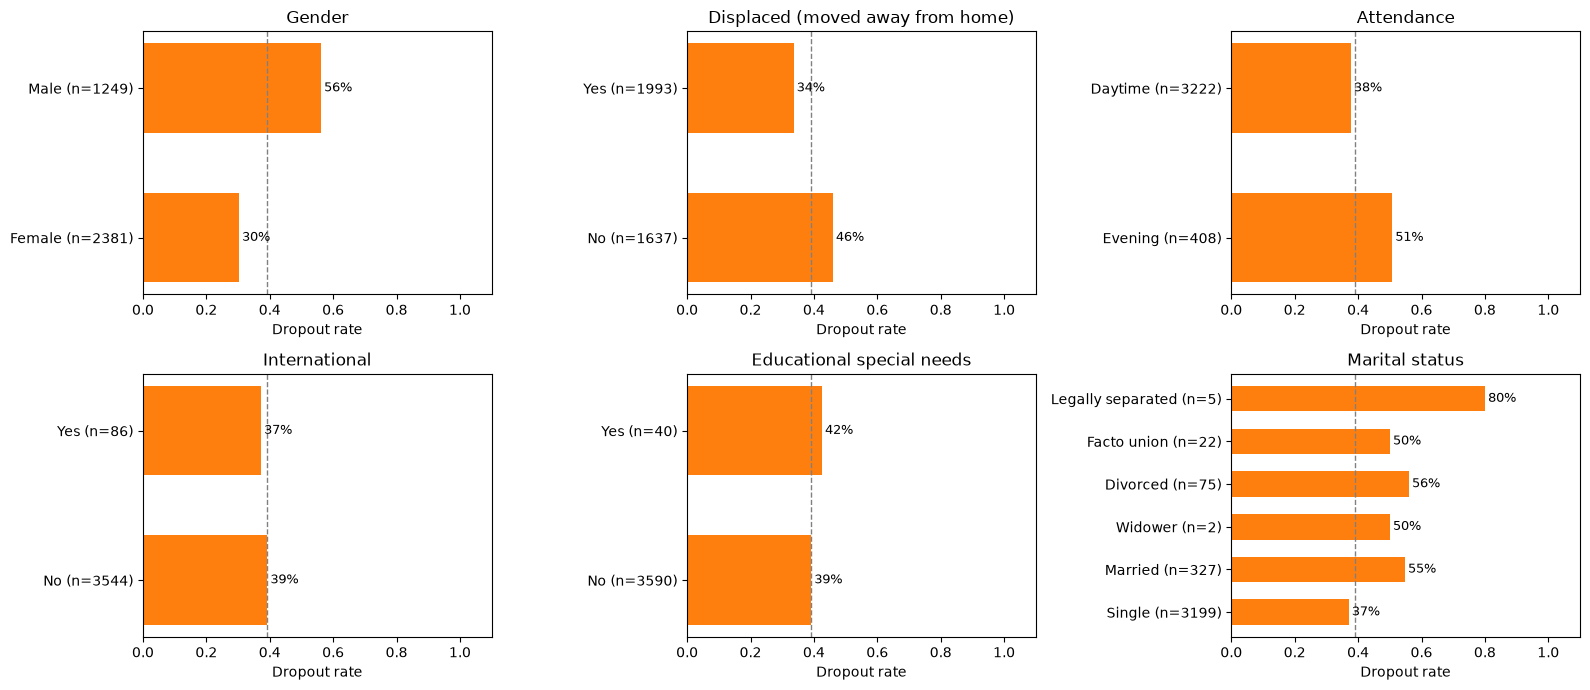

In [13]:
MARITAL_NAMES = {1: "Single", 2: "Married", 3: "Widower", 4: "Divorced", 5: "Facto union", 6: "Legally separated"}

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
plot_dropout_rate("gender", axes[0, 0], labels={0: "Female", 1: "Male"}, title="Gender")
plot_dropout_rate("displaced", axes[0, 1], labels=yes_no, title="Displaced (moved away from home)")
plot_dropout_rate("daytime_evening_attendance", axes[0, 2], labels={0: "Evening", 1: "Daytime"}, title="Attendance")
plot_dropout_rate("international", axes[1, 0], labels=yes_no, title="International")
plot_dropout_rate("educational_special_needs", axes[1, 1], labels=yes_no, title="Educational special needs")
plot_dropout_rate("marital_status", axes[1, 2], labels=MARITAL_NAMES, title="Marital status")
plt.tight_layout()
plt.show()

- **Gender:** male students dropped out 56% of the time vs 30% for female students. This is a big gap, but gender is a sensitive attribute so we need to think about whether it's fair to use it in a model that flags students (we'll come back to this in ethics).
- **Displaced:** students who moved away from home dropped out *less* (34% vs 46%).
- **Evening students** dropped out more than daytime students (51% vs 38%).
- **International** and **special needs** barely make a difference, and there are only 86 and 40 students in those groups, so these probably won't help the model much.
- **Marital status:** single students dropped out the least (37%), and married/divorced students more (55%+). The other groups are tiny (2-22 students) so they aren't reliable. This is probably related to age too, since married students tend to be older.

### 6. Family Background

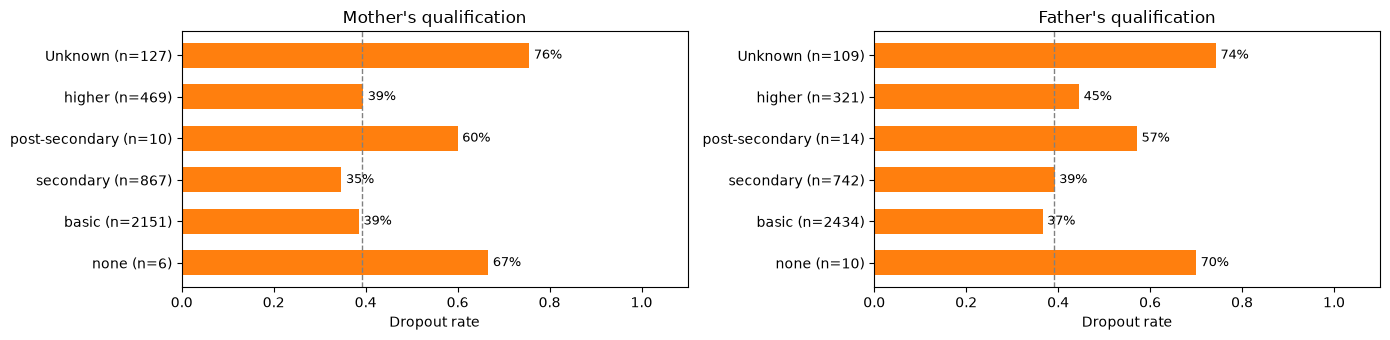

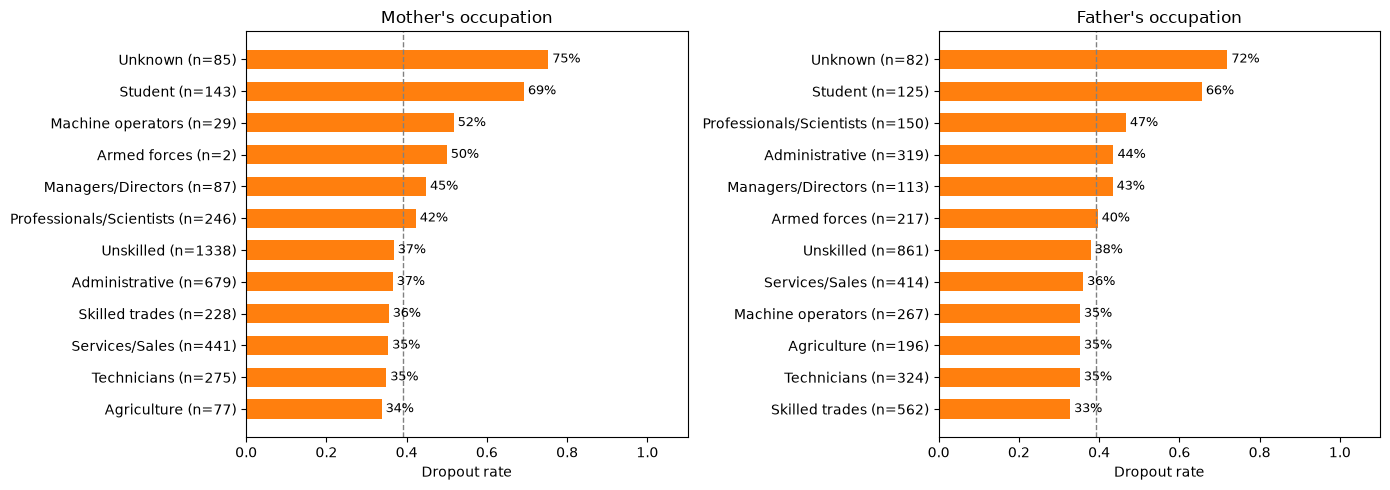

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
plot_dropout_rate("mother_qualification", axes[0], title="Mother's qualification")
plot_dropout_rate("father_qualification", axes[1], title="Father's qualification")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_dropout_rate("mother_occupation", axes[0], sort=True, title="Mother's occupation")
plot_dropout_rate("father_occupation", axes[1], sort=True, title="Father's occupation")
plt.tight_layout()
plt.show()

This one was more surprising:
- For the main education levels (basic, secondary, higher), the dropout rate is pretty close to the overall 39%. So **parents' education level by itself doesn't seem to matter much**. `none` and `post-secondary` look high but only have 6-14 students, so we can't really trust those bars.
- Parent occupation is also mostly flat around 33-45%.
- The groups that really stand out are **`Unknown`** (~72-76% dropout for both parents, for both qualification and occupation) and parents listed as a **`Student`** (~66-69%).

So it's not really *what* the parents do, it's whether the info is missing. Our guess is that students who didn't fill in their parent's info might be less engaged with the application overall, or might be older students where this info is less relevant. Either way, an "unknown parent info" flag could be a useful feature.

### 7. Prior Schooling

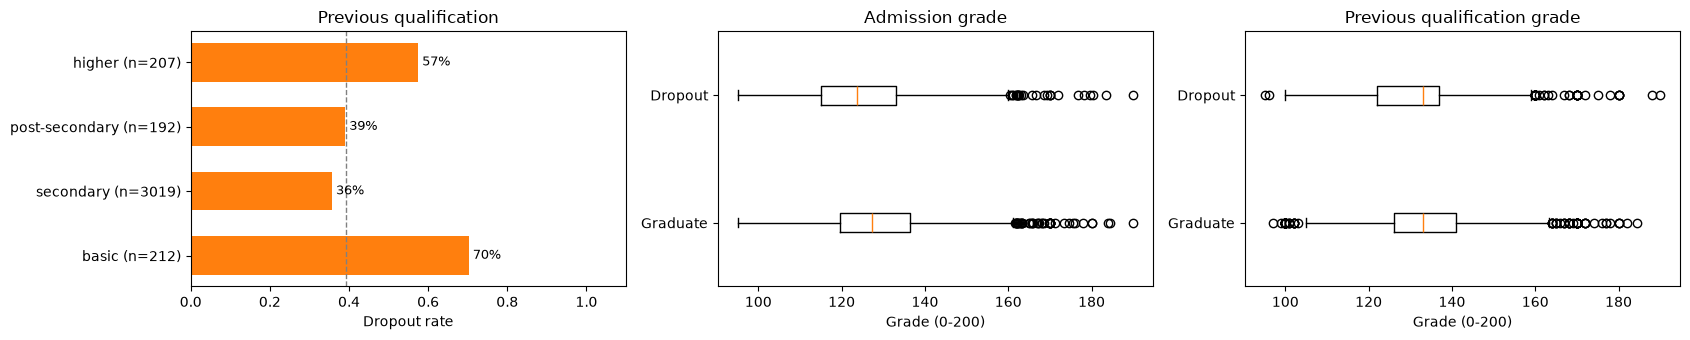

,admission_grade,previous_qualification_grade
dropout,,
Graduate,127.4,133.1
Dropout,123.6,133.1


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.5))

plot_dropout_rate("previous_qualification", axes[0], title="Previous qualification")

for ax, col, title in [(axes[1], "admission_grade", "Admission grade"),
                       (axes[2], "previous_qualification_grade", "Previous qualification grade")]:
    ax.boxplot([df.loc[df["dropout"] == 0, col], df.loc[df["dropout"] == 1, col]], orientation="horizontal")
    ax.set_yticks([1, 2], ["Graduate", "Dropout"])
    ax.set_xlabel("Grade (0-200)")
    ax.set_title(title)

plt.tight_layout()
plt.show()

df.groupby("dropout")[["admission_grade", "previous_qualification_grade"]].median().rename(index={0: "Graduate", 1: "Dropout"})

- Students who came in with only a **basic** qualification (didn't finish secondary) dropped out **70%** of the time. Students with a **higher** education qualification already also dropped out a lot (57%), maybe because they're older or switching careers.
- **Grades help less than we expected.** Dropouts have a slightly lower admission grade (median 123.6 vs 127.4) but the boxes overlap almost completely. The previous qualification grade has the exact same median for both groups (133.1).
- The two grade columns are also correlated with each other (~0.58), so they're partly giving the same information.

### 8. Course
The course codes are mapped to names using the UCI data dictionary so the plot is readable.

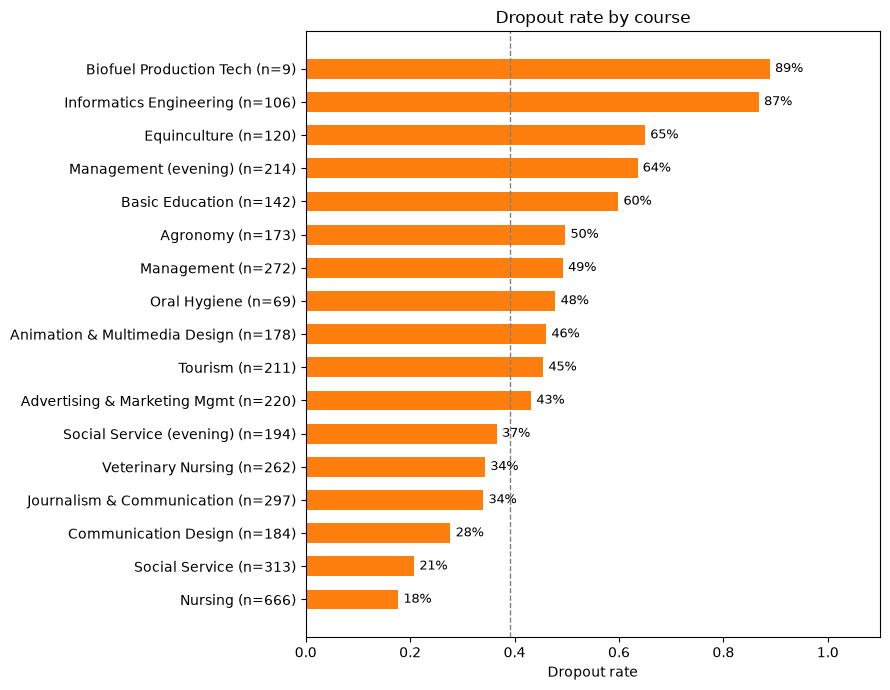

In [16]:
COURSE_NAMES = {
    33: "Biofuel Production Tech", 171: "Animation & Multimedia Design", 8014: "Social Service (evening)",
    9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing",
    9119: "Informatics Engineering", 9130: "Equinculture", 9147: "Management",
    9238: "Social Service", 9254: "Tourism", 9500: "Nursing", 9556: "Oral Hygiene",
    9670: "Advertising & Marketing Mgmt", 9773: "Journalism & Communication",
    9853: "Basic Education", 9991: "Management (evening)",
}

fig, ax = plt.subplots(figsize=(9, 7))
plot_dropout_rate("course", ax, labels=COURSE_NAMES, sort=True, title="Dropout rate by course")
plt.tight_layout()
plt.show()

The course a student picks matters a lot. **Nursing (18%)** and **Social Service (21%)** have the lowest dropout rates, while **Informatics Engineering (87%)** and **Equinculture (65%)** are much higher. Biofuel Production Tech is at 89% but only has 9 students. Course is technically a choice and not a "background" thing, but it's known at enrollment so it's fair to use in the model.

### 9. Economic Indicators
These three columns are national stats for the year the student enrolled, so every student from the same year gets the same values.

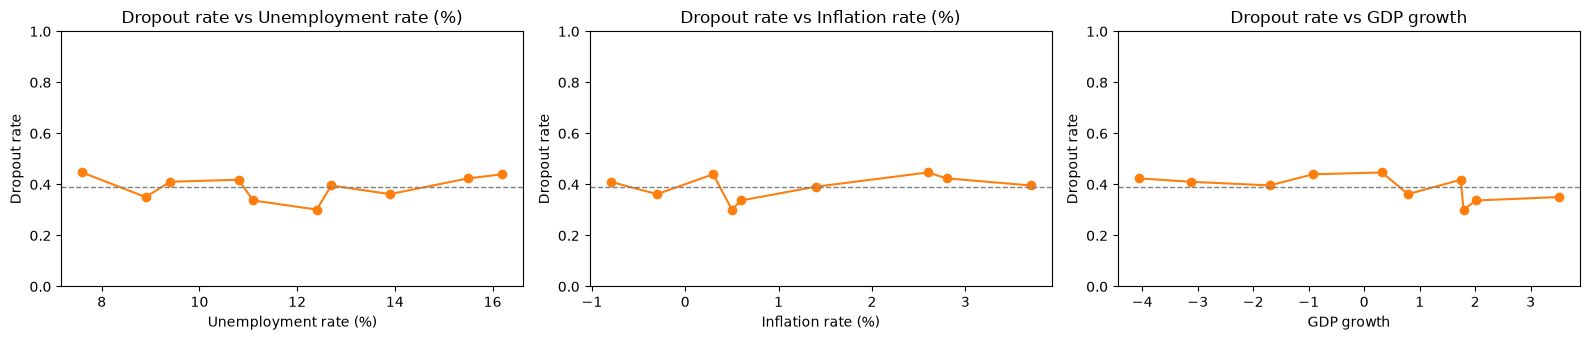

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, col, title in [(axes[0], "unemployment_rate", "Unemployment rate (%)"),
                       (axes[1], "inflation_rate", "Inflation rate (%)"),
                       (axes[2], "gdp", "GDP growth")]:
    rates = df.groupby(col)["dropout"].mean()
    ax.plot(rates.index, rates.values, marker="o", color=DROP_COLOR)
    ax.axhline(OVERALL_RATE, color="gray", linestyle="--", linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel(title)
    ax.set_ylabel("Dropout rate")
    ax.set_title(f"Dropout rate vs {title}")
plt.tight_layout()
plt.show()

The dropout rate just bounces around 30-45% no matter what the economy was doing, with no clear trend. These columns probably won't help much, and since there are only ~10 unique values they're basically just acting as a "which year did they enroll" column.

### 10. Correlation With Dropout
To get one overall ranking, we calculated the correlation between each numeric/binary column and `dropout`. Positive means "more likely to drop out", negative means "less likely". This only works for numeric columns and only picks up straight-line relationships, so it misses things like `course` and the `Unknown` groups from above, but it's a nice summary.

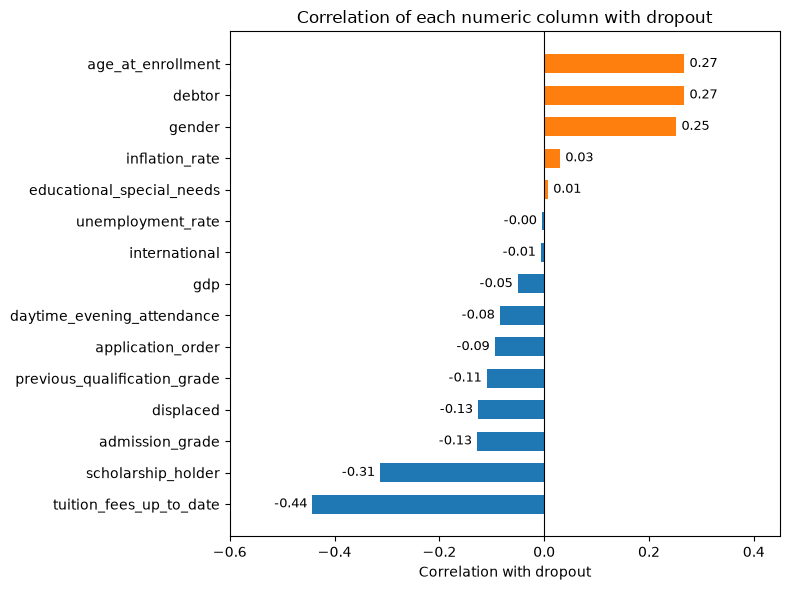

In [18]:
corr = df.select_dtypes("number").corr()["dropout"].drop("dropout").sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = [DROP_COLOR if c > 0 else GRAD_COLOR for c in corr]
ax.barh(corr.index, corr.values, color=colors, height=0.6)
ax.axvline(0, color="black", linewidth=0.8)
for i, c in enumerate(corr):
    ax.text(c + (0.01 if c > 0 else -0.01), i, f"{c:.2f}", va="center", ha="left" if c > 0 else "right", fontsize=9)
ax.set_xlim(-0.6, 0.45)
ax.set_xlabel("Correlation with dropout")
ax.set_title("Correlation of each numeric column with dropout")
plt.tight_layout()
plt.show()

This lines up with what we saw in the plots. The strongest are **tuition fees up to date (-0.44)**, **scholarship (-0.31)**, **age (+0.27)**, **debtor (+0.27)** and **gender (+0.25)**. The economic indicators, international, and special needs are all close to 0.

### 11. Summary of Findings

**Back to our question: does background affect dropout?** Yes, but some parts of a student's background matter a lot more than others.

| Factor | Effect on dropout |
|---|---|
| Financial (tuition, debtor, scholarship) | **Very strong** (tuition not up to date → 94% dropout, but see the leakage concern in section 4) |
| Age at enrollment | **Strong** (17-20 → 26%, 26-30 → 70%) |
| Course | **Strong** (18% to 87% depending on the course) |
| Gender | **Moderate** (male 56% vs female 30%) |
| Previous qualification | **Moderate** (basic → 70%) |
| Parent info missing / parent is a student | **Moderate** (~66-76%) |
| Marital status, attendance, displaced | Weak to moderate |
| Parents' actual education / occupation level | Weak |
| Admission & previous grades | Weak |
| International, special needs, economic indicators | Basically none |

# Modelling

### 1. Train/Test Split
We split the data once here so both models are tested on the same students.
- 80% train, 20% test.
- `stratify=y` keeps the dropout rate about the same in both sets.
- `random_state=42` gives the same split every time.
- `y` is the `dropout` column (1 = Dropout, 0 = Graduate).

In [19]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df.columns if c != "dropout"]
X = df[feature_cols]
y = df["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("train:", X_train.shape, "test:", X_test.shape)
print("dropout rate -> train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

train: (2904, 23) test: (726, 23)
dropout rate -> train: 0.392 | test: 0.391


### 2. Baseline Model
Our baseline predicts the most common outcome for every student, like we did in class. In our training data that's `Graduate`.

The decision tree has to beat this to be useful.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

LABELS = ["Graduate", "Dropout"]   # 0 = Graduate, 1 = Dropout

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("baseline always predicts:", LABELS[baseline_pred[0]])
print("baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("confusion matrix:\n", confusion_matrix(y_test, baseline_pred))
print(classification_report(y_test, baseline_pred, target_names=LABELS, zero_division=0))

baseline always predicts: Graduate
baseline accuracy: 0.609
confusion matrix:
 [[442   0]
 [284   0]]
              precision    recall  f1-score   support

    Graduate       0.61      1.00      0.76       442
     Dropout       0.00      0.00      0.00       284

    accuracy                           0.61       726
   macro avg       0.30      0.50      0.38       726
weighted avg       0.37      0.61      0.46       726



The baseline gets **60.9% accuracy** by predicting that every student graduates. But it catches **0 of the 284 dropouts**.

So the decision tree needs to:
- beat **60.9%** accuracy, and
- catch at least some dropouts.